# 11 Model Comparison

**Question:** which approach best distinguishes genuine from manipulated image–caption pairs?
This notebook compares saved predictions on the same rows. It does not train or change any model.

| Model | Source | How component scores are produced |
|---|---|---|
| Combined baseline model | 06 + 07 | Caption score from the text-only model; image score from the image-only model |
| Early fusion | 09 | A neural classifier uses image and caption embeddings and comparison features together |
| Stacking | 10 | Classifier scores, handcrafted features and image–caption similarities are combined |

All three provide an image score and a caption score internally. We evaluate only the overall pair label, `is_fake`: **fake if either component is manipulated; genuine if neither is manipulated**.

We use the same combination rule for all three approaches:

$$s_{\mathrm{pair}} = 1-(1-p_{\mathrm{image}})(1-p_{\mathrm{text}}).$$

A high score from either component raises the pair score. We treat this as a **combined manipulation score**; interpreting it as an exact probability would require independence and calibration assumptions.

**Workflow:** load validation predictions → choose one F1 threshold per model → evaluate frozen test predictions in the final cell. Test results did not guide model or threshold choices.

## 0. Setup

In [58]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve,
)

# Support running from either the repository root or notebooks/.
PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src" / "evaluation.py").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT))
from src.evaluation import best_f1_threshold, combine_fake_score

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PREDICTIONS_DIR = PROJECT_ROOT / "results" / "predictions"

# Earlier cells load validation only. The final cell enables test reporting.
# Run All therefore evaluates test when it reaches that final cell.
RUN_TEST = False
sns.set_theme(style="whitegrid")

## 1. Load and align predictions

Each prediction file contains `row_id` and image and/or caption scores. We match scores to dataset labels using `row_id`, not file order. All required files must be present, with unique IDs, exact split coverage and finite scores between 0 and 1.

Only validation is loaded here. The same loader is called for test in the final cell. Overall scores are recalculated with the shared formula, so every approach follows the same rule.

As the code runs, previews show the loaded labels, each model's scores after matching `row_id`, and finally the three combined pair scores beside the true labels (`0 = genuine`, `1 = fake`). Higher scores indicate more suspicion; no thresholds have been applied yet.

The function returns `val` (labels) and `val_scores` (combined scores) in memory for later sections. No files are created or modified. Previews are enabled for validation here and omitted from the final test call.

In [59]:
SOURCES = {
    "Text only": ("text_model", ["p_text_fake"]),
    "Image only": ("image_model", ["p_image_fake"]),
    "Early fusion": ("early_fusion", ["p_image_fake", "p_text_fake"]),
    "Stacking": ("multimodal_stacking", ["p_image_fake", "p_text_fake"]),
}
BASELINE = "Combined baseline model"
MODEL_ORDER = [BASELINE, "Early fusion", "Stacking"]


def load_scores(split, preview=False):
    """Return split labels and aligned pair scores for all three approaches."""
    labels = pd.read_parquet(
        PROCESSED_DIR / f"{split}.parquet",
        columns=["row_id", "fake_cls", "is_fake"],
    )
    if labels["row_id"].isna().any() or not labels["row_id"].is_unique:
        raise ValueError(f"{split}: label row IDs must be nonmissing and unique")
    if set(labels["is_fake"].unique()) != {0, 1} or labels["fake_cls"].isna().any():
        raise ValueError(f"{split}: both binary classes and nonmissing manipulation labels are required")

    if preview:
        print(f"Loaded {len(labels):,} labels from data/processed/{split}.parquet")
        display(labels.head(3))

    loaded = {}
    for name, (prefix, columns) in SOURCES.items():
        path = PREDICTIONS_DIR / f"{prefix}_{split}.parquet"
        if not path.is_file():
            raise FileNotFoundError(f"Required {name} predictions are missing: {path}")
        pred = pd.read_parquet(path, columns=["row_id", *columns])
        if pred["row_id"].isna().any() or not pred["row_id"].is_unique:
            raise ValueError(f"{name}: prediction row IDs must be nonmissing and unique")
        if (len(pred) != len(labels)
                or not labels["row_id"].isin(pred["row_id"]).all()):
            raise ValueError(f"{name}: prediction IDs do not exactly match the {split} split")
        aligned = labels[["row_id"]].merge(
            pred, on="row_id", how="left", sort=False, validate="one_to_one"
        )
        values = aligned[columns].to_numpy()
        if not np.isfinite(values).all() or ((values < 0) | (values > 1)).any():
            raise ValueError(f"{name}: scores must be finite and between 0 and 1")
        loaded[name] = aligned
        if preview:
            print(f"{name}: {path.relative_to(PROJECT_ROOT)} — aligned by row_id")
            display(aligned.head(3).round(3))

    scores = {
        BASELINE: combine_fake_score(
            loaded["Image only"]["p_image_fake"], loaded["Text only"]["p_text_fake"]
        )
    }
    for name in MODEL_ORDER[1:]:
        scores[name] = combine_fake_score(
            loaded[name]["p_image_fake"], loaded[name]["p_text_fake"]
        )
    if preview:
        combined = labels.assign(**{f"{name} score": score for name, score in scores.items()})
        print("Combined pair scores (first 5 rows); is_fake: 0 = genuine, 1 = fake.")
        display(combined.head(5).round(3))
    return labels, scores


val, val_scores = load_scores("validation", preview=True)


Loaded 22,126 labels from data/processed/validation.parquet


,row_id,fake_cls,is_fake
0,validation_000000,orig,0
1,validation_000001,face_swap,1
2,validation_000002,text_swap,1


Text only: results/predictions/text_model_validation.parquet — aligned by row_id


,row_id,p_text_fake
0,validation_000000,0.170
1,validation_000001,0.147
2,validation_000002,0.270


Image only: results/predictions/image_model_validation.parquet — aligned by row_id


,row_id,p_image_fake
0,validation_000000,0.577
1,validation_000001,0.512
2,validation_000002,0.053


... (2 outputs left out)

Stacking: results/predictions/multimodal_stacking_validation.parquet — aligned by row_id


,row_id,p_image_fake,p_text_fake
0,validation_000000,0.570,0.461
1,validation_000001,0.434,0.345
2,validation_000002,0.028,0.979


Combined pair scores (first 5 rows); is_fake: 0 = genuine, 1 = fake.


,row_id,fake_cls,is_fake,Combined baseline model score,Early fusion score,Stacking score
0,validation_000000,orig,0,0.649,0.846,0.768
1,validation_000001,face_swap,1,0.584,0.460,0.629
2,validation_000002,text_swap,1,0.308,1.000,0.980
3,validation_000003,orig,0,0.010,0.069,0.039
4,validation_000004,orig,0,0.346,0.439,0.291


## 2. Choose decision thresholds on validation

A score is converted into a label using **score ≥ threshold → fake**; otherwise it is genuine.
For example, a pair scoring 0.60 is flagged at a threshold of 0.40 but not at 0.70.

- **Precision:** among flagged pairs, the fraction actually manipulated.
- **Recall:** among manipulated pairs, the fraction flagged.
- **F1:** the harmonic mean of precision and recall: `2 × precision × recall / (precision + recall)`.

For each model, the shared helper (best_f1_threshold from src/evaluation.py) searches up to 197 candidate cutoffs between the 1st and 99th percentiles of its validation scores and selects the cutoff with the highest validation F1. This is the best among the searched candidates, not an exhaustive search.

The threshold is a score cutoff, **not an F1 score**. Thresholds differ because models have different score distributions. They are fixed here and applied unchanged to test; no test labels are used to select them. All subsequent threshold-based results use these same cutoffs.

In [60]:
thresholds = {
    name: best_f1_threshold(val["is_fake"], score)
    for name, score in val_scores.items()
}
display(pd.Series(thresholds, name="Validation-selected threshold")
        .rename_axis("Model").to_frame().round(3))

,Validation-selected threshold
Model,
Combined baseline model,0.392
Early fusion,0.390
Stacking,0.404


## 3. Pair-level comparison: metrics and plots

The functions below define the final comparison; they do not load or evaluate test data yet.

The main table reports **ROC-AUC, precision, recall and F1**. ROC-AUC measures how well scores rank fake pairs above genuine pairs (0.5 indicates random ranking; higher is better). The other three metrics use each model's validation-selected threshold.

**Confusion matrices:** rows are true labels and columns are predicted labels. Counts and percentages within each true class show genuine pairs incorrectly flagged (false positives) and manipulated pairs missed (false negatives). All matrices share the same colour scale.

**ROC plot:** one figure overlays all three models across thresholds. It shows recall against the fraction of genuine pairs incorrectly flagged. Curves nearer the top left indicate better performance; the dashed diagonal represents random ranking. It does not depend on the selected F1 threshold.

In [61]:
def results_table(labels, scores):
    """Pair-level metrics; use validation-selected cutoffs for binary decisions."""
    y = labels["is_fake"].to_numpy()
    rows = []
    for name, score in scores.items():
        predicted = score >= thresholds[name]
        rows.append({
            "Model": name,
            "ROC-AUC": roc_auc_score(y, score),
            "Precision": precision_score(y, predicted, zero_division=0),
            "Recall": recall_score(y, predicted, zero_division=0),
            "F1": f1_score(y, predicted, zero_division=0),
        })
    return pd.DataFrame(rows).set_index("Model")


def plot_confusion_matrices(labels, scores, split):
    fig, axes = plt.subplots(1, len(scores), figsize=(14, 4.3), squeeze=False)
    for ax, (name, score) in zip(axes[0], scores.items()):
        counts = confusion_matrix(
            labels["is_fake"], score >= thresholds[name], labels=[0, 1]
        )
        fractions = counts / counts.sum(axis=1, keepdims=True)
        annotations = np.array([
            [f"{counts[r, c]:,}\n({fractions[r, c]:.1%})" for c in range(2)]
            for r in range(2)
        ])
        sns.heatmap(
            fractions, annot=annotations, fmt="", cmap="Purples",
            vmin=0, vmax=1, cbar=False, square=True, ax=ax,
            xticklabels=["Genuine", "Fake"], yticklabels=["Genuine", "Fake"],
        )
        ax.set_title(f"{name}\nThreshold = {thresholds[name]:.3f}")
        ax.set_xlabel("Predicted pair label")
        ax.set_ylabel("True pair label")
        ax.tick_params(axis="y", labelrotation=0)
    fig.suptitle(f"Pair-level confusion matrices ({split})")
    fig.tight_layout()
    plt.show()


def plot_roc(labels, scores, split):
    fig, ax = plt.subplots(figsize=(7, 5))
    for name, score in scores.items():
        fpr, recall, _ = roc_curve(labels["is_fake"], score)
        auc = roc_auc_score(labels["is_fake"], score)
        ax.plot(fpr, recall, linewidth=2, label=f"{name} (AUC = {auc:.3f})")
    ax.plot([0, 1], [0, 1], "--", color="grey", label="Random ranking")
    ax.set(
        xlim=(0, 1), ylim=(0, 1.02),
        xlabel="False-positive rate (genuine pairs flagged)",
        ylabel="Recall (fake pairs detected)",
        title=f"Pair-level ROC comparison ({split})",
    )
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()

## 4. Error analysis by manipulation type

**Purpose:** identify which kinds of manipulated pairs each overall detector catches or misses. Similar overall F1 scores can hide different weaknesses.

We group the binary pair decisions by the dataset's known `fake_cls` labels. For example, if 70 of 100 `text_swap` pairs are flagged, their detection rate is 70%. The model is **not** asked to predict the manipulation type.

The table uses the same validation-selected F1 thresholds as the main comparison. For `orig`, the flagged fraction is a **false-positive rate**; for every manipulated category, it is a **detection rate (recall)**. Counts show how many pairs support each rate. A category containing `&` has both listed manipulations.

In [63]:
def manipulation_table(labels, scores):
    """Group pair decisions by known manipulation type; this does not classify the type."""
    groups = labels["fake_cls"]
    table = groups.value_counts(sort=False).rename("Pairs").to_frame()
    for name, score in scores.items():
        # 1. Apply the same F1 threshold used in the main results.
        flagged = pd.Series(score >= thresholds[name], index=labels.index)
        # 2. Group by the dataset's known manipulation categories.
        # 3. Mean of True/False is the fraction flagged in each category.
        table[name] = flagged.groupby(groups).mean()
    # Show genuine pairs first, then alphabetically ordered manipulation types.
    order = (["orig"] if "orig" in table.index else []) + sorted(
        category for category in table.index if category != "orig"
    )
    return table.loc[order].rename_axis("Dataset manipulation type")

## 5. Final test evaluation

The final cell loads **test labels and saved test predictions**, then displays the main comparison, three confusion matrices, one ROC plot and the manipulation-type table. Thresholds remain fixed from validation.

**Run All evaluates test at this point:** the cell explicitly sets `RUN_TEST = True`. To skip evaluation, change that line in this final cell to `RUN_TEST = False`. 

All four sources must first export their test prediction files. This notebook does not generate them or retrain models.

Final test comparison: 50,705 image–caption pairs


,ROC-AUC,Precision,Recall,F1
Model,,,,
Combined baseline model,0.806,0.750,0.92,0.826
Early fusion,0.828,0.744,0.94,0.831
Stacking,0.879,0.801,0.92,0.856


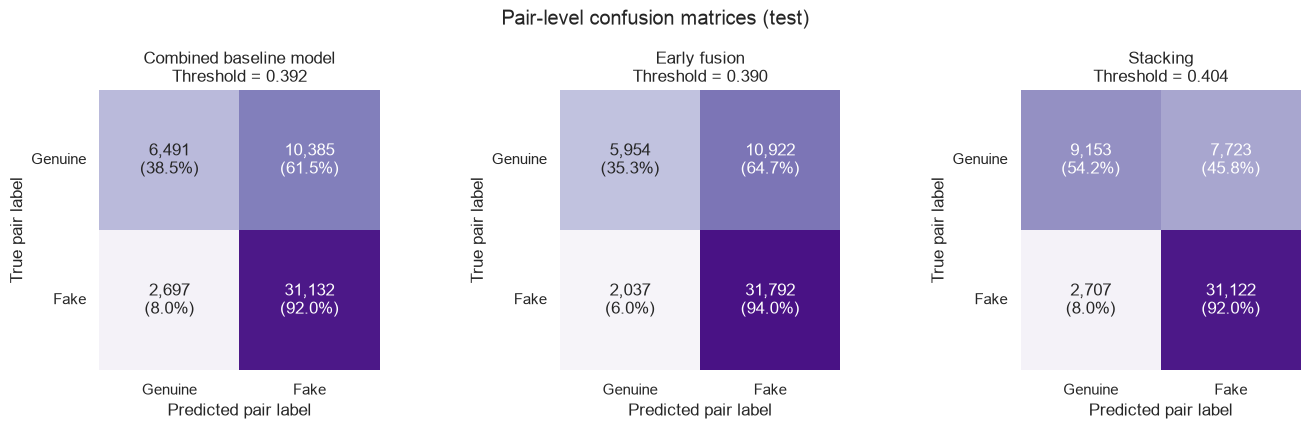

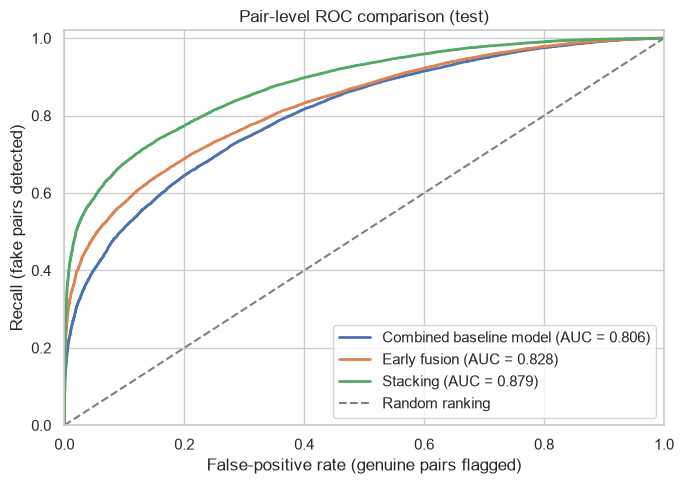

Fraction flagged by dataset manipulation type (orig = false-positive rate):


,Pairs,Combined baseline model,Early fusion,Stacking
Dataset manipulation type,,,,
orig,"16,876",61.5%,64.7%,45.8%
face_attribute,"8,921",95.6%,95.0%,91.9%
face_attribute&text_attribute,886,98.5%,98.5%,97.0%
face_attribute&text_swap,"2,529",98.3%,99.8%,99.4%
face_swap,"10,515",93.1%,91.1%,90.1%
face_swap&text_attribute,"1,118",98.8%,95.3%,96.9%
face_swap&text_swap,"2,935",96.5%,99.2%,99.3%
text_attribute,"1,973",87.9%,80.1%,74.8%
text_swap,"4,952",76.3%,96.4%,93.1%


In [64]:
# Enable final reporting with frozen predictions and validation-selected thresholds.
# Set False HERE to skip test evaluation, including during Run All.
RUN_TEST = True

if RUN_TEST:
    test, test_scores = load_scores("test")
    print(f"Final test comparison: {len(test):,} image–caption pairs")
    results_test = results_table(test, test_scores)
    display(results_test.round(3))
    plot_confusion_matrices(test, test_scores, "test")
    plot_roc(test, test_scores, "test")
    print("Fraction flagged by dataset manipulation type (orig = false-positive rate):")
    display(manipulation_table(test, test_scores).style.format({
        "Pairs": "{:,.0f}", **{name: "{:.1%}" for name in MODEL_ORDER}
    }))
else:
    print("Test evaluation skipped. Only validation predictions have been loaded.")